# Trabalho 1 de Aprendizado de Máquina
## Dataset: Seoul Bike Sharing Demand
#### Integrantes: Felipe Pasinato Rossoni, Renan Augusto da Silva Zen, Stefano Fiorioli Dahmer

O dataset contém informações sobre quantas bicicletas foram alugadas por hora na cidade de Seoul (capital da Coreia do Sul), com informações sobre: Data, Hora, Qtd de Bicicletas alugadas, Temperatura, Chuva, Neve, Umidade, Estação, Feriado, entre outros.

O objetivo do modelo será prever, dadas as condições de um determinado dia/hora, quantas bicicletas serão alugadas.

Atributos do dataset:
Date, Rented Bike Count, Hour, Temperature (°C), Humidity (%), Wind speed (m/s), Visibility (10m), Dew point temperature (°C), Solar Radiation (Mj/m²), Rainfall (mm), Snowfall (cm), Seasons, Holiday, Functioning Day.


In [1]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor


In [2]:
df = pd.read_csv('SeoulBikeData.csv')
print(df.head())
print(df.info())

         Date  Rented Bike Count  Hour  Temperature  Humidity  Wind speed  \
0  01/12/2017                254     0         -5.2        37         2.2   
1  01/12/2017                204     1         -5.5        38         0.8   
2  01/12/2017                173     2         -6.0        39         1.0   
3  01/12/2017                107     3         -6.2        40         0.9   
4  01/12/2017                 78     4         -6.0        36         2.3   

   Visibility  Dew point temperature  Solar Radiation  Rainfall  Snowfall  \
0        2000                  -17.6              0.0       0.0       0.0   
1        2000                  -17.6              0.0       0.0       0.0   
2        2000                  -17.7              0.0       0.0       0.0   
3        2000                  -17.6              0.0       0.0       0.0   
4        2000                  -18.6              0.0       0.0       0.0   

  Seasons     Holiday Functioning Day  
0  Winter  No Holiday             

## Pré-processamento

In [3]:
# deixa so dias que functioning day = Yes no dataset (dias com No sempre tem bike count = 0)
df = df[df['Functioning Day'] == 'Yes'].copy()
df = df.drop('Functioning Day', axis=1)

# separa dia e mes pra ver tendencias
df['Date'] = pd.to_datetime(df['Date'], format='%d/%m/%Y')
df['Month'] = df['Date'].dt.month
df['DayOfWeek'] = df['Date'].dt.dayofweek # 0 = segunda, 6 = domingo
df = df.drop('Date', axis=1)

X = df.drop('Rented Bike Count', axis=1)
y = df['Rented Bike Count']

# separa em treino e teste sem embaralhar (para nao receber informacoes futuras)
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, shuffle=False
)


In [4]:
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore')) # evita colunas redundantes
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])



In [8]:
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.dummy import DummyRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore', category=UserWarning) # Avisos do onehot sobre estações não vistas nos primeiros folds (IA)

# validacao cruzada temporal com 5 folds: cada fold treina no passado e valida no periodo seguinte
tscv = TimeSeriesSplit(n_splits=5)

# metricas avaliadas (o sklearn retorna rmse e mae negativos, por isso inverte o sinal depois)
scoring = {
    'rmse': 'neg_root_mean_squared_error',
    'mae': 'neg_mean_absolute_error',
    'r2': 'r2'
}

# modelos do spot-check com hiperparametros padrao
modelos = {
    'Dummy': DummyRegressor(), # baseline: sempre preve a media
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(),
    'KNN': KNeighborsRegressor(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': HistGradientBoostingRegressor(random_state=42)
}

In [9]:
resultados = []
rmse_folds = {} # guarda o rmse de cada fold pra usar no grafico

for nome, modelo in modelos.items():
    # preprocessor dentro do pipeline pra ser ajustado so no treino de cada fold (evita data leakage)
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('model', modelo)])
    cv = cross_validate(pipe, X_train, y_train, cv=tscv, scoring=scoring)

    rmse_folds[nome] = -cv['test_rmse']

    # media e desvio padrao das metricas nos 5 folds
    resultados.append({
        'Modelo': nome,
        'RMSE': f"{-cv['test_rmse'].mean():.2f} ± {cv['test_rmse'].std():.2f}",
        'MAE': f"{-cv['test_mae'].mean():.2f} ± {cv['test_mae'].std():.2f}",
        'R²': f"{cv['test_r2'].mean():.3f} ± {cv['test_r2'].std():.3f}"
    })

df_resultados = pd.DataFrame(resultados)
df_resultados

,Modelo,RMSE,MAE,R²
0,Dummy,676.52 ± 294.68,510.39 ± 226.70,-0.466 ± 0.291
1,Linear Regression,495.16 ± 200.13,393.88 ± 176.15,0.197 ± 0.135
2,Ridge,495.10 ± 200.13,393.82 ± 176.06,0.198 ± 0.136
3,KNN,416.12 ± 149.72,300.44 ± 111.01,0.386 ± 0.147
4,Decision Tree,363.37 ± 135.04,251.54 ± 103.72,0.514 ± 0.122
5,Random Forest,290.55 ± 114.80,205.69 ± 89.13,0.690 ± 0.110
6,Gradient Boosting,283.24 ± 117.80,196.52 ± 88.58,0.688 ± 0.192


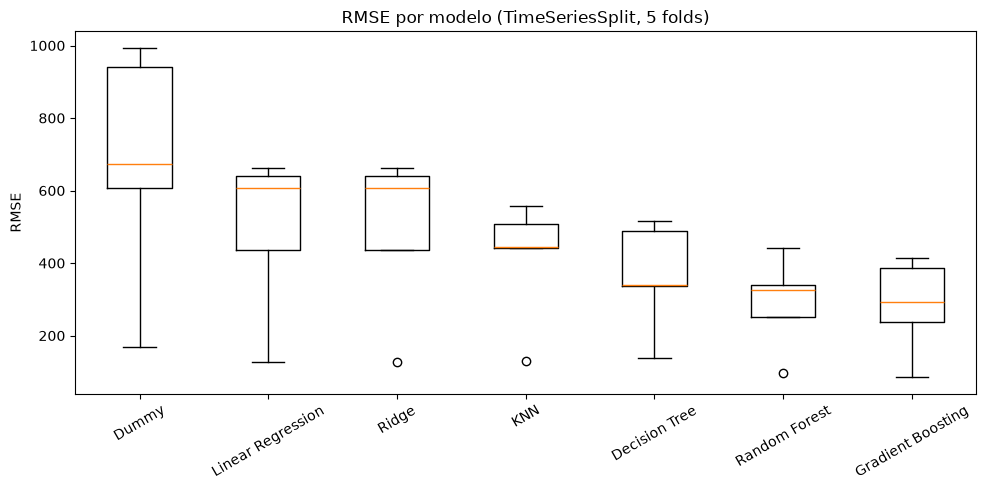

In [10]:
# boxplot do rmse por fold pra comparar os modelos (menor e melhor)
plt.figure(figsize=(10, 5))
plt.boxplot(list(rmse_folds.values()), tick_labels=list(rmse_folds.keys()))
plt.ylabel('RMSE')
plt.title('RMSE por modelo (TimeSeriesSplit, 5 folds)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()